<center>
    <h2>Master 2</h2>
    <h5 style="margin-top: 5px">Sciences de l’Océan, de l’Atmosphère et du Climat</h5>
    <h1>TP - Système climatique</h1>
  <br>
    <strong>Contact:</strong> isaline.bossert@meteo.fr / romain.torres4@gmail.com

</center>


<div style="padding: 1rem; background-color: #d1ecf1; border: 1px solid #bee5eb; border-radius: 4px; margin: 1rem 0;">
  <strong>💡 Instructions</strong> 
    
Ce notebook est à <i>compléter</i> avec vos réponses aux questions posées et à <i>envoyer</i> par mail au plus tard <u>une semaine après la dernière séance de TP</u>. Merci de renommer le notebook pour y incorporer vos noms de famille (ex: TP-Climat-2026-Nom1_Nom2_Nom3.ipynb)
  - une attention particulière doit être donnée aux <b>figures</b> (clareté, titre, axes, légendes, etc..) 
  - les analyses portent sur vos <b>connaissances théoriques</b> en lien avec le cours "Système Climatique" (J. Cattiaux) sont attendues
  - la <b>curiosité scientifique</b> est bien sûre encouragée: même si les questions sont là pour aiguiller le TP, n'hésitez pas à demander des clarifications où d'éventuelles pistes d'analyses supplémentaires ;)
    

⚠️ Lors de la dernière séance, chaque groupe présentera son notebook (sujet + analyses effectuées):
  - durée max de 12 minutes de restitution qui doit être <b>claire</b> et <b>synthétique</b>. Il n'est pas nécessaire de créer un support de présentation particulier.
  - la restitution est suivie d'un <b>tour de questions</b> de la part des élèves puis des enseignantes pour vérifier les notions

<center>
        <h1>Sujet 5: Réponses impulsionnelles à des émissions des carbones</h1>
  <br>
    <strong>Main topics covered here:</strong>
</center>

## Introduction

Introduire les puits et les sources avec un schéma

## Load Python modules and simulation outputs

Along this notebook, Python codes are used to analyse model outputs.
You first need to import and load required modules:

In [131]:
# manipulate file and data
import os
import numpy  as np
import xarray as xr
import pandas as pd

# plotting
import matplotlib
import matplotlib.pyplot as plt

# statistics
from scipy.optimize import fmin
from scipy.optimize import curve_fit

In [35]:
# load BERN data - co2
df_co2 = pd.read_csv("./../data/Bern3Dv2/IRF_co2.csv")
df_co2["yr_after_pulse"] = np.arange(0,2001,1) # model year

In [36]:
# load BERN data - land
df_land = pd.read_csv("./../data/Bern3Dv2/IRF_land.csv")
df_land["yr_after_pulse"] = np.arange(0,2001,1) # model year

In [37]:
# load BERN data - ocean
df_ocean = pd.read_csv("./../data/Bern3Dv2/IRF_ocean.csv")
df_ocean["yr_after_pulse"] = np.arange(0,2001,1) # model year

#### Question 1: 

* Tracer les outputs du modele BERN background 500pm (médiane et intervalle de confiance)


<a id="section-1"></a>
## 1. Earth system response to a pulse of CO$_2$

Text(0, 0.5, 'CO$_2$ fraction remaining in atm. (%)')

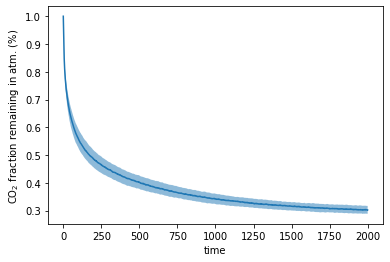

In [23]:
# Tracer les outputs du modele BERN background 500pm 
plt.plot(df_co2["yr_after_pulse"], df_co2["bg_500_50"])
plt.fill_between(df_co2["yr_after_pulse"], df_co2["bg_500_16"], df_co2["bg_500_84"], alpha=0.5)

plt.xlabel("time")
plt.ylabel(r"CO$_2$ fraction remaining in atm. (%)")

#### Question 2: 

* What about other background CO2 ?
* How to interpret those different response ?

Text(0, 0.5, 'CO$_2$ fraction remaining in atm. (%)')

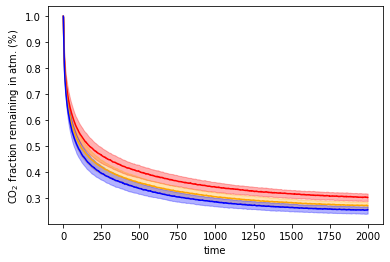

In [30]:
# Tracer les outputs du modele BERN background 500pm 
plt.plot(df_co2["yr_after_pulse"], df_co2["bg_500_50"], color="red")
plt.fill_between(df_co2["yr_after_pulse"], df_co2["bg_500_16"], df_co2["bg_500_84"], alpha=0.3, color="red")

plt.plot(df_co2["yr_after_pulse"], df_co2["bg_450_50"], color="orange")
plt.fill_between(df_co2["yr_after_pulse"], df_co2["bg_450_16"], df_co2["bg_450_84"], alpha=0.3, color="orange")

plt.plot(df_co2["yr_after_pulse"], df_co2["bg_425_50"], color="blue")
plt.fill_between(df_co2["yr_after_pulse"], df_co2["bg_425_16"], df_co2["bg_425_84"], alpha=0.3, color="blue")

plt.xlabel("time")
plt.ylabel(r"CO$_2$ fraction remaining in atm. (%)")

#### Question 3: 

* Now, ptite question de cours : 
Quels sont les processus clefs qui retire du co2 de l'atm ?
Pression partielle a la surface de l'océan en premier lieu 
Et pour la biosphere c la photosynthèse
* Confirm your knwoledge with model data

Text(0.5, 1.0, 'b. land')

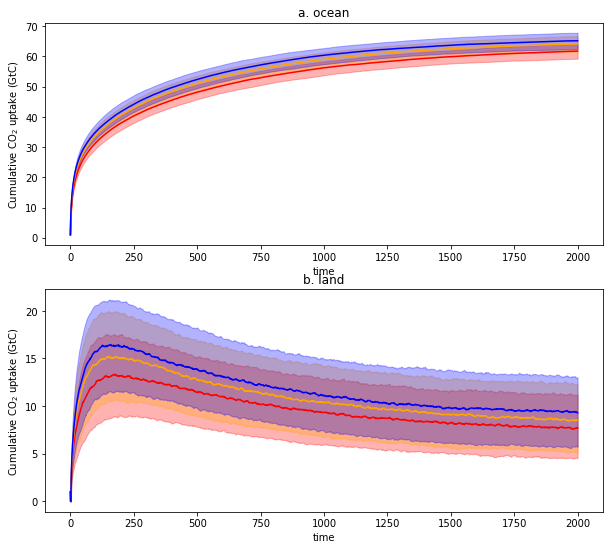

In [128]:
fig, axes = plt.subplots(2,1, figsize=(10, 9))

# Ocean
axes[0].plot(df_ocean["yr_after_pulse"], df_ocean["bg_500_50"], color="red")
axes[0].fill_between(df_ocean["yr_after_pulse"], df_ocean["bg_500_16"], df_ocean["bg_500_84"], alpha=0.3, color="red")

axes[0].plot(df_ocean["yr_after_pulse"], df_ocean["bg_450_50"], color="orange")
axes[0].fill_between(df_ocean["yr_after_pulse"], df_ocean["bg_450_16"], df_ocean["bg_450_84"], alpha=0.3, color="orange")

axes[0].plot(df_ocean["yr_after_pulse"], df_ocean["bg_425_50"], color="blue")
axes[0].fill_between(df_ocean["yr_after_pulse"], df_ocean["bg_425_16"], df_ocean["bg_425_84"], alpha=0.3, color="blue")

axes[0].set_xlabel("time")
axes[0].set_ylabel(r"Cumulative CO$_2$ uptake (GtC)")
axes[0].set_title("a. ocean")
# Land
axes[1].plot(df_land["yr_after_pulse"], df_land["bg_500_50"], color="red")
axes[1].fill_between(df_land["yr_after_pulse"], df_land["bg_500_16"], df_land["bg_500_84"], alpha=0.3, color="red")

axes[1].plot(df_land["yr_after_pulse"], df_land["bg_450_50"], color="orange")
axes[1].fill_between(df_land["yr_after_pulse"], df_land["bg_450_16"], df_land["bg_450_84"], alpha=0.3, color="orange")

axes[1].plot(df_land["yr_after_pulse"], df_land["bg_425_50"], color="blue")
axes[1].fill_between(df_land["yr_after_pulse"], df_land["bg_425_16"], df_land["bg_425_84"], alpha=0.3, color="blue")

axes[1].set_xlabel("time")
axes[1].set_ylabel(r"Cumulative CO$_2$ uptake (GtC)")
axes[1].set_title("b. land")

<a id="section-1"></a>
## 2. Analytical representation

#### Question 4: 

* How much stays in the atmosphere after 10 years, 100 years, 1000 years ?
* How can we qualify the temporal evolution given by this model? Does this model behave linearly in function of time?
* A quoi vous fait penser la courbe de la question 1 precedente ? en terme de fonction analytique ?
* Tester un fit simple
* what do you think about your fit ?

__help:__ use function fmin

In [124]:
# fit dynamical parameters

# initialization
a_0 = 0
a_1 = 0
tau_1 = 0

time = df_co2["yr_after_pulse"]
def err_1exp(var):
    fit = var[0] + var[1]*np.exp(-time/var[2])
    return sum(( fit - (df_co2["bg_500_50"]))**2)  # RMSE (Sum of error squared)
[a_0, a_1, tau_1] = fmin(err_1exp,[0, 1, 100],disp=False)

Text(0, 0.5, 'Error')

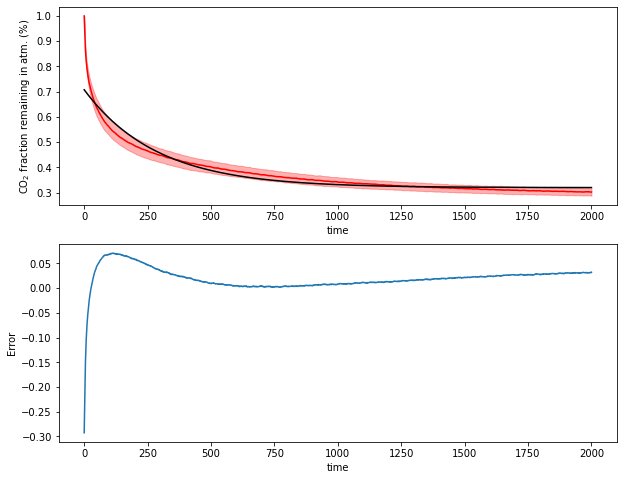

In [125]:
# Tracer les outputs du modele BERN background 500pm 
fig, axes = plt.subplots(2, 1, figsize=(10, 8))
axes[0].plot(df_co2["yr_after_pulse"], df_co2["bg_500_50"], color="red")
axes[0].fill_between(df_co2["yr_after_pulse"], df_co2["bg_500_16"], df_co2["bg_500_84"], alpha=0.3, color="red")


axes[0].set_xlabel("time")
axes[0].set_ylabel(r"CO$_2$ fraction remaining in atm. (%)")

# Fit
year = np.arange(0,2001,1)
axes[0].plot(year, a_0 + a_1*np.exp(-year/tau_1), color="k")


# Error in fit

axes[1].plot(year, a_0 + a_1*np.exp(-year/tau_1) - df_co2["bg_500_16"])
axes[1].set_xlabel("time")
axes[1].set_ylabel(r"Error")


#### Question 5: 

* Try improving this fit 

In [126]:
# fit dynamical parameters

# initialization
a_0 = 0
a_1 = 0
tau_1 = 0
a_2 = 0
tau_2 = 0

time = df_co2["yr_after_pulse"]
def err_2exp(var):
    fit = var[0] + var[1]*np.exp(-time/var[2]) + (1-var[1]-var[0])*np.exp(-time/var[3])
    return sum(( fit - (df_co2["bg_500_50"]))**2)  # RMSE (Sum of error squared)
[a_0, a_1, tau_1, tau_2] = fmin(err_2exp,[0, 1, 100, 100],disp=False)

a_2 = 1 - a_1 - a_0


/usr/lib/python3/dist-packages/pandas/core/arraylike.py:364: RuntimeWarning: overflow encountered in exp
  result = getattr(ufunc, method)(*inputs, **kwargs)


Text(0, 0.5, 'Error')

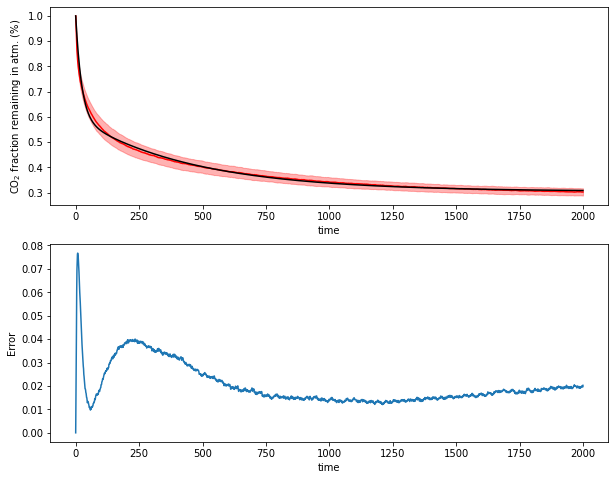

In [127]:
# Tracer les outputs du modele BERN background 500pm 
fig, axes = plt.subplots(2, 1, figsize=(10, 8))
axes[0].plot(df_co2["yr_after_pulse"], df_co2["bg_500_50"], color="red")
axes[0].fill_between(df_co2["yr_after_pulse"], df_co2["bg_500_16"], df_co2["bg_500_84"], alpha=0.3, color="red")


axes[0].set_xlabel("time")
axes[0].set_ylabel(r"CO$_2$ fraction remaining in atm. (%)")

# Fit
year = np.arange(0,2001,1)
axes[0].plot(year, a_0 + a_1*np.exp(-year/tau_1) + a_2*np.exp(-year/tau_2), color="k")

# Error in fit

axes[1].plot(year, a_0 + a_1*np.exp(-year/tau_1) + a_2*np.exp(-year/tau_2) - df_co2["bg_500_16"])
axes[1].set_xlabel("time")
axes[1].set_ylabel(r"Error")


#### Question 6: 

* mmmmh, still lacking some information, try to add another exp

In [129]:
# fit dynamical parameters

# initialization
a_0 = 0
a_1 = 0
tau_1 = 0
a_2 = 0
tau_2 = 0
a_3 = 0
tau_3 = 0

time = df_co2["yr_after_pulse"]
def err_3exp(var):
    fit = var[0] + var[1]*np.exp(-time/var[2]) + var[3]*np.exp(-time/var[4]) + (1-var[3]-var[1]-var[0])*np.exp(-time/var[5])
    return sum(( fit - (df_co2["bg_500_50"]))**2)  # RMSE (Sum of error squared)
[a_0, a_1, tau_1, a_2, tau_2, tau_3] = fmin(err_3exp,[0.5, 0.2, 1, 0.5, 10, 100],disp=False)

a_3 = 1 - a_2 - a_1 - a_0


/usr/lib/python3/dist-packages/pandas/core/arraylike.py:364: RuntimeWarning: overflow encountered in exp
  result = getattr(ufunc, method)(*inputs, **kwargs)


Text(0, 0.5, 'Error')

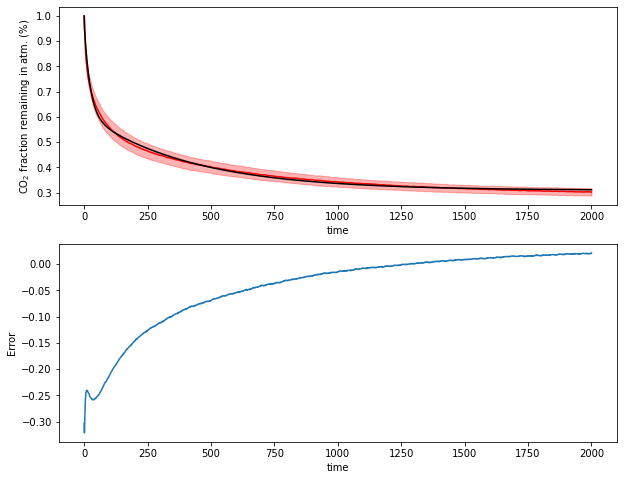

In [130]:
# Tracer les outputs du modele BERN background 500pm 
fig, axes = plt.subplots(2, 1, figsize=(10, 8))
axes[0].plot(df_co2["yr_after_pulse"], df_co2["bg_500_50"], color="red")
axes[0].fill_between(df_co2["yr_after_pulse"], df_co2["bg_500_16"], df_co2["bg_500_84"], alpha=0.3, color="red")


axes[0].set_xlabel("time")
axes[0].set_ylabel(r"CO$_2$ fraction remaining in atm. (%)")

# Fit
year = np.arange(0,2001,1)
intermediaire = a_0 + a_1*np.exp(-time/tau_1) + a_2*np.exp(-time/tau_2) + a_3*np.exp(-time/tau_3)
axes[0].plot(year, intermediaire, color="k")

# Error in fit

axes[1].plot(year, a_0 + a_1*np.exp(-year/tau_1) + a_2*np.exp(-year/tau_2) - df_co2["bg_500_16"])
axes[1].set_xlabel("time")
axes[1].set_ylabel(r"Error")


In [118]:
a_0, a_1, a_2, a_3

(0.34371321424577106,
 -0.6695458195635815,
 -0.3676361128892592,
 1.6934687182070696)

In [119]:
tau_1, tau_2, tau_3

(111.24045339867, 77.12461977345001, 101.6863527521734)

In [137]:
def func(x, a_0, a_1, tau_1, a_2, tau_2, tau_3):
    return a_0 + a_1*np.exp(-x/tau_1) + a_2*np.exp(-x/tau_2) + (1-a_0-a_1-a_2)-np.exp(-x/tau_3)

popt, pcov = curve_fit(func, np.arange(1, 2002), df_co2['bg_500_50'])

/tmp/ipykernel_28426/2394422017.py:2: RuntimeWarning: overflow encountered in exp
  return a_0 + a_1*np.exp(-x/tau_1) + a_2*np.exp(-x/tau_2) + (1-a_0-a_1-a_2)-np.exp(-x/tau_3)
/tmp/ipykernel_28426/2394422017.py:4: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, pcov = curve_fit(func, np.arange(1, 2002), df_co2['bg_500_50'])


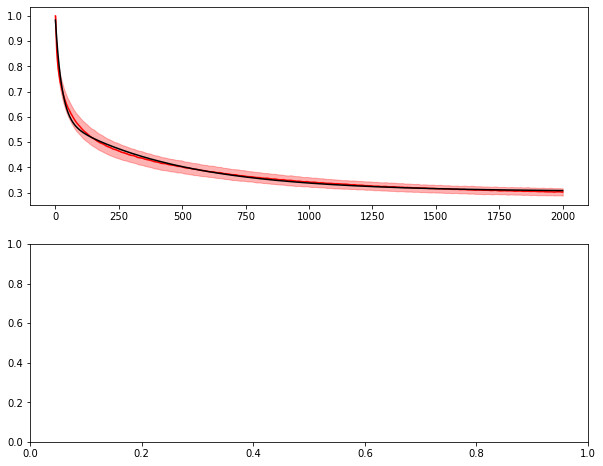

In [140]:
fig, axes = plt.subplots(2, 1, figsize=(10, 8))
axes[0].plot(df_co2["yr_after_pulse"], df_co2["bg_500_50"], color="red")
axes[0].fill_between(df_co2["yr_after_pulse"], df_co2["bg_500_16"], df_co2["bg_500_84"], alpha=0.3, color="red")


axes[0].plot(np.arange(2001), func(np.arange(1, 2002), *popt), c='k')

#### Question 4:
* _According your knowledge, which Earth system components are simulated by the
various terms of the IRF equation ?_
* _What do they represent ? How do they evolve individually ?_

__Help__ : What are the units of $\tau_{C,}$ and $a_{C,}$ ?
